# Simulating Option Charm under the BSM Framework

## Objective

This notebook studies how an option's Charm behaves under the Black–Scholes–Merton (BSM) framework, and how it responds to changes in moneyness, time to maturity, volatility, the risk-free rate and the dividend yield. Calls and puts are analysed separately wherever their formulas differ. It also connects Charm to the two first-order Greeks it is built from: Delta and Theta.

## What Charm measures

Charm (also called delta decay) is the rate at which an option's Delta changes as time passes, with all other inputs held constant:

$$
\text{Charm} = \frac{\partial \Delta}{\partial t} = -\frac{\partial \Delta}{\partial T}
$$

where $\Delta = \frac{\partial V}{\partial S}$ is the option's Delta, $t$ is calendar time, and $T$ is the time remaining to maturity in years.

Charm is a **second-order Greek**: it differentiates the option value twice, once with respect to the stock price and once with respect to time. The order of differentiation does not matter, so Charm can be read in two equivalent ways:

$$
\text{Charm} = \frac{\partial}{\partial t}\left(\frac{\partial V}{\partial S}\right) = \frac{\partial}{\partial S}\left(\frac{\partial V}{\partial t}\right) = \frac{\partial \Theta}{\partial S}
$$

So Charm is both **how fast Delta drifts as time passes** and **the slope of the Theta curve** with respect to the stock price. This notebook shows both readings.

**Why it matters:** a trader who hedges an option by holding $\Delta$ shares has to adjust the hedge over time even if the stock price never moves. Charm tells them how much the hedge drifts each day.

**Sign convention:** Charm is measured as calendar time passes, the same direction as Theta in notebook 01. A positive Charm means Delta rises as time passes; a negative Charm means it falls. Some sources define Charm as $\partial \Delta / \partial T$ instead, which flips the sign.

**Scaling:** the formula gives Charm per year. All values and plots in this notebook report Charm per calendar day, i.e. the change in Delta over one day:

$$
\text{Charm}_{\text{day}} = \frac{\text{Charm}_{\text{year}}}{365}
$$

This matches the per-day scaling used for Theta in notebook 01. Like Theta, Charm is an instantaneous rate: it describes how fast Delta is changing right now, not a fixed amount it changes by every day until expiry.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## Charm Formula under BSM

Under BSM with a continuous dividend yield $q$, Delta is

$$
\Delta_{\text{call}} = e^{-qT}N(d_1), \qquad \Delta_{\text{put}} = -e^{-qT}N(-d_1)
$$

Differentiating Delta with respect to calendar time gives Charm (per year):

$$
\text{Charm}_{\text{call}} = qe^{-qT}N(d_1) - e^{-qT}N'(d_1)\,\frac{2(r-q)T - d_2\sigma\sqrt{T}}{2T\sigma\sqrt{T}}
$$

$$
\text{Charm}_{\text{put}} = -qe^{-qT}N(-d_1) - e^{-qT}N'(d_1)\,\frac{2(r-q)T - d_2\sigma\sqrt{T}}{2T\sigma\sqrt{T}}
$$

where

$$
d_1 = \frac{\ln(S/K) + \left(r - q + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

and

- $S$: current price of the underlying
- $K$: strike price
- $T$: time to maturity, in years
- $r$: continuously compounded risk-free rate
- $q$: continuous dividend yield
- $\sigma$: volatility of the underlying
- $N(x)$: standard normal cumulative distribution function
- $N'(x) = \frac{1}{\sqrt{2\pi}}e^{-x^2/2}$: standard normal probability density function

### The three parts of Charm

Splitting the fraction into two pieces gives three parts, each with its own meaning:

$$
\text{Charm}_{\text{call}} = \underbrace{e^{-qT}N'(d_1)\,\frac{d_2}{2T}}_{(1)\ \text{convergence}}\ \underbrace{-\ e^{-qT}N'(d_1)\,\frac{r-q}{\sigma\sqrt{T}}}_{(2)\ \text{drift}}\ \underbrace{+\ qe^{-qT}N(d_1)}_{(3)\ \text{dividends}}
$$

For puts, parts (1) and (2) are identical, and part (3) becomes $-qe^{-qT}N(-d_1)$.

1. **Convergence**, $e^{-qT}N'(d_1)\frac{d_2}{2T}$: at expiry, Delta can only take its final value: 1 for an in-the-money call and 0 for an out-of-the-money call (−1 and 0 for puts). As time passes, Delta moves toward that final value. The sign follows $d_2$: when the stock is likely to finish above the strike ($d_2 > 0$), it pushes Delta up; when it is likely to finish below ($d_2 < 0$), it pushes Delta down. It is zero at $d_2 = 0$, where the outcome is a 50-50 call, small far from the strike, where Delta has already reached its final value, and it grows rapidly as $T \to 0$ because of the $\frac{1}{T}$ factor.

2. **Drift**, $-e^{-qT}N'(d_1)\frac{r-q}{\sigma\sqrt{T}}$: BSM prices options as if the stock grows on average at the rate $r - q$. When $r > q$, the growth expected over the remaining time raises the chance of finishing above the strike, which raises Delta. As time passes, less of that growth remains, so Delta falls. The drift part is therefore negative when $r > q$, positive when $q > r$, and zero when $r = q$. It is identical for calls and puts, largest near the money where $N'(d_1)$ peaks, and larger when volatility is low, because the expected growth then matters more relative to the stock's random swings.

3. **Dividends**, $+qe^{-qT}N(d_1)$ for calls and $-qe^{-qT}N(-d_1)$ for puts: Delta is scaled by $e^{-qT}$, because dividends paid before expiry drain value from the stock. Even a call that is certain to be exercised has a Delta below 1. As time passes, fewer dividends remain, $e^{-qT}$ rises toward 1, and call Delta rises (put Delta falls toward −1). This part is zero when $q = 0$.

**Calls vs puts:** call Delta minus put Delta always equals $e^{-qT}$. With $q = 0$ this is always exactly 1, so both Deltas change by the same amount every day and call Charm equals put Charm. With $q > 0$, the gap $e^{-qT}$ itself grows as time passes, so call Charm exceeds put Charm by $qe^{-qT}$ per year, the same at every stock price.

In [2]:
DAYS_PER_YEAR = 365


def d1_d2(S, K, T, r, q, sigma):
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2


def delta(S, K, T, r, q, sigma, option):
    d1, _ = d1_d2(S, K, T, r, q, sigma)
    if option == "call":
        return np.exp(-q * T) * norm.cdf(d1)
    if option == "put":
        return -np.exp(-q * T) * norm.cdf(-d1)
    raise ValueError("option must be 'call' or 'put'")


def theta(S, K, T, r, q, sigma, option):
    d1, d2 = d1_d2(S, K, T, r, q, sigma)
    decay = -S * np.exp(-q * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
    if option == "call":
        carry = -r * K * np.exp(-r * T) * norm.cdf(d2) + q * S * np.exp(-q * T) * norm.cdf(d1)
    elif option == "put":
        carry = r * K * np.exp(-r * T) * norm.cdf(-d2) - q * S * np.exp(-q * T) * norm.cdf(-d1)
    else:
        raise ValueError("option must be 'call' or 'put'")
    return (decay + carry) / DAYS_PER_YEAR


def charm_parts(S, K, T, r, q, sigma, option):
    d1, d2 = d1_d2(S, K, T, r, q, sigma)
    shared = np.exp(-q * T) * norm.pdf(d1)
    convergence = shared * d2 / (2 * T)
    drift = -shared * (r - q) / (sigma * np.sqrt(T))

    if option == "call":
        dividend = q * np.exp(-q * T) * norm.cdf(d1)
    elif option == "put":
        dividend = -q * np.exp(-q * T) * norm.cdf(-d1)
    else:
        raise ValueError("option must be 'call' or 'put'")

    return convergence / DAYS_PER_YEAR, drift / DAYS_PER_YEAR, dividend / DAYS_PER_YEAR


def charm(S, K, T, r, q, sigma, option):
    return sum(charm_parts(S, K, T, r, q, sigma, option))

## Base Case and Parameter Ranges

Unless a plot states otherwise, every calculation uses the base case below. Each plot varies one or two parameters at a time and holds the rest at their base values. These are the same choices as in notebook 01, so the two notebooks can be compared directly.

| Parameter | Base case | Values used when varied |
|---|---|---|
| Stock price $S$ | 100 | 50 to 150, in steps of 0.1 |
| Strike price $K$ | 100 | fixed |
| Time to maturity $T$ | 1 year | 1 week, 1 month, 3 months, 1 year; and a continuous range from 1 day to 2 years |
| Volatility $\sigma$ | 20% | 10%, 20%, 40% |
| Risk-free rate $r$ | 5% | 0%, 5%, 10% |
| Dividend yield $q$ | 0% | 0%, 5%, 10% |

**Moneyness** is measured as $S/K$, from 0.5 to 1.5:

- $S/K < 1$: the call is out of the money (OTM) and the put is in the money (ITM).
- $S/K = 1$: both are at the money (ATM).
- $S/K > 1$: the call is ITM and the put is OTM.

When comparing ITM, ATM and OTM options directly, we use $S/K = 0.9$, $1.0$ and $1.1$.

**Notes on these choices:**

- $K$ is fixed at 100 because Delta, and therefore Charm, depends on $S$ and $K$ only through the ratio $S/K$. Changing $K$ while keeping $S/K$ fixed leaves Charm unchanged.
- $S$ moves in steps of 0.1 because, close to expiry, Charm is concentrated in a very narrow band around ATM. A coarser step would miss its peaks.
- Maturities are converted to years using calendar days: 1 week = $7/365$, 1 month = $30/365$, 3 months = $90/365$.
- The shortest maturity is 1 day, because the formula divides by $T$ and cannot be evaluated at $T = 0$.
- The values of $r$ and $q$ are set wider than typical market levels so that their effects are clearly visible.
- **Calls and puts:** with $q = 0$, call and put Charm are identical (shown in the base-case plot below). Plots that keep $q = 0$ therefore show calls only; the dividend-yield plot shows both.

In [3]:
K = 100
T_BASE = 1.0
SIGMA_BASE = 0.20
R_BASE = 0.05
Q_BASE = 0.0

S_GRID = np.linspace(50, 150, 1001)
moneyness = S_GRID / K
DAYS = np.arange(1, 731)
T_GRID = DAYS / DAYS_PER_YEAR

MATURITIES = {"1 week": 7 / 365, "1 month": 30 / 365, "3 months": 90 / 365, "1 year": 1.0}
MONEYNESS_LEVELS = [0.9, 1.0, 1.1]
SIGMAS = [0.10, 0.20, 0.40]
RATES = [0.00, 0.05, 0.10]
DIV_YIELDS = [0.00, 0.05, 0.10]

## Base-Case Charm Values

Charm predicts how much Delta will change over one day. As a check, the table compares it with the actual change: Delta is computed today ($T = 1$ year) and again one calendar day later ($T = 1 - \frac{1}{365}$), with the stock price and all other inputs unchanged.

Parameters: $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$, at $S/K = 0.9$, $1.0$ and $1.1$, for calls and puts.

In [4]:
one_day = 1 / DAYS_PER_YEAR
rows = []

for option in ["call", "put"]:
    for m in MONEYNESS_LEVELS:
        delta_today = delta(m * K, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, option)
        delta_tomorrow = delta(m * K, K, T_BASE - one_day, R_BASE, Q_BASE, SIGMA_BASE, option)
        rows.append({"option": option, "S/K": m,
                     "delta today": delta_today, "delta tomorrow": delta_tomorrow,
                     "actual change": delta_tomorrow - delta_today,
                     "charm (per day)": charm(m * K, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, option)})

pd.DataFrame(rows).round(6)

,option,S/K,delta today,delta tomorrow,actual change,charm (per day)
0,call,0.9,0.429832,0.429359,-0.000472,-0.000472
1,call,1.0,0.636831,0.636651,-0.000180,-0.000180
2,call,1.1,0.795754,0.795804,0.000049,0.000049
3,put,0.9,-0.570168,-0.570641,-0.000472,-0.000472
4,put,1.0,-0.363169,-0.363349,-0.000180,-0.000180
5,put,1.1,-0.204246,-0.204196,0.000049,0.000049


### Observations

1. **Charm predicts the daily change in Delta:** in every row, the actual change in Delta over one day matches Charm to six decimal places (for example −0.000472 at $S/K = 0.9$). This confirms both the formula and the per-day scaling.

2. **The changes are small with a year left, but they add up:** the ATM call's Delta falls by about 0.00018 per day, so over a month it drifts by roughly 30 × 0.00018 ≈ 0.005, even if the stock price never moves. A Delta hedge has to be adjusted for this.

3. **The sign depends on moneyness:** at $S/K = 0.9$ (OTM call), Delta falls as time passes (−0.000472), moving toward 0. At $S/K = 1.1$ (ITM call), it rises (+0.000049), moving toward 1. At ATM it also falls (−0.000180), even though the ATM call is slightly more likely than not to finish in the money. The plots below explain why.

4. **Calls and puts match:** with $q = 0$, call and put Delta always differ by exactly 1 (for example 0.429832 and −0.570168 at $S/K = 0.9$). Each day, both change by the same amount, so their Charm is identical.

## Delta vs Moneyness at Different Maturities

Before plotting Charm itself, this plot shows what Charm describes: how the whole Delta curve changes shape as expiry approaches.

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for four maturities: 1 week, 1 month, 3 months and 1 year
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** call Delta (left) and put Delta (right). The table below gives call Delta at $S/K = 0.9$, $1.0$ and $1.1$ for each maturity.

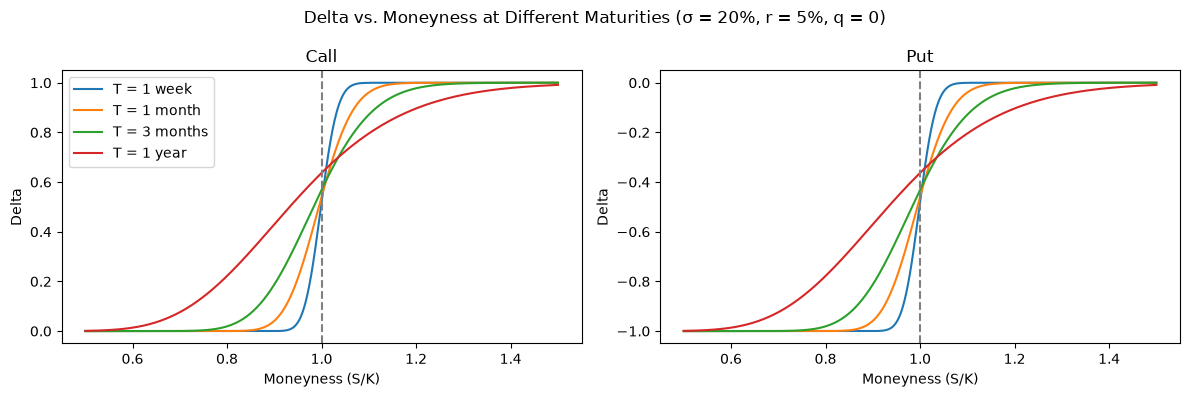

,maturity,call delta at S/K = 0.9,call delta at S/K = 1.0,call delta at S/K = 1.1
0,1 week,0.0001,0.5193,0.9998
1,1 month,0.0412,0.5400,0.9610
2,3 months,0.1875,0.5690,0.8715
3,1 year,0.4298,0.6368,0.7958


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, option in zip(axes, ["call", "put"]):
    for label, T in MATURITIES.items():
        ax.plot(moneyness, delta(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE, option), label=f"T = {label}")
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")
    ax.set_ylabel("Delta")

axes[0].legend()
fig.suptitle("Delta vs. Moneyness at Different Maturities (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

rows = []
for label, T in MATURITIES.items():
    row = {"maturity": label}
    for m in MONEYNESS_LEVELS:
        row[f"call delta at S/K = {m}"] = delta(m * K, K, T, R_BASE, Q_BASE, SIGMA_BASE, "call")
    rows.append(row)

pd.DataFrame(rows).round(4)

### Observations

1. **The Delta curve sharpens into a step as expiry approaches:** with 1 year left, call Delta rises gradually from about 0 to about 1 over a wide range of stock prices. With 1 week left, it jumps from 0 to 1 within a few percent of the strike. At expiry it becomes a step: 1 above the strike and 0 below (0 and −1 for puts).

2. **Each option's Delta heads toward its final value:** at $S/K = 1.1$, call Delta rises from 0.7958 at 1 year to 0.8715 at 3 months, 0.9610 at 1 month and 0.9998 at 1 week. The option behaves more and more like the stock itself. At $S/K = 0.9$, it falls from 0.4298 to 0.1875, 0.0412 and 0.0001, as the option heads toward expiring worthless. Charm measures how fast this movement happens.

3. **ATM Delta heads toward 0.5:** at $S/K = 1.0$, call Delta falls from 0.6368 at 1 year to 0.5193 at 1 week. With a long time left, the stock's expected growth makes finishing above the strike more likely than not. As time runs out, less growth remains and the outcome approaches a 50-50 split. This is the drift part of Charm at work.

4. **The put curves are the call curves shifted down by 1:** with $q = 0$, put Delta = call Delta − 1, so the put curves have exactly the same shape and change in exactly the same way over time.

## Charm vs Moneyness (Base Case)

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls (solid) and puts (dashed). With $q = 0$ the two are identical, so the curves lie on top of each other.

The dashed vertical line at $S/K = 1$ marks ATM. Below the horizontal line at 0, Delta falls as time passes; above it, Delta rises.

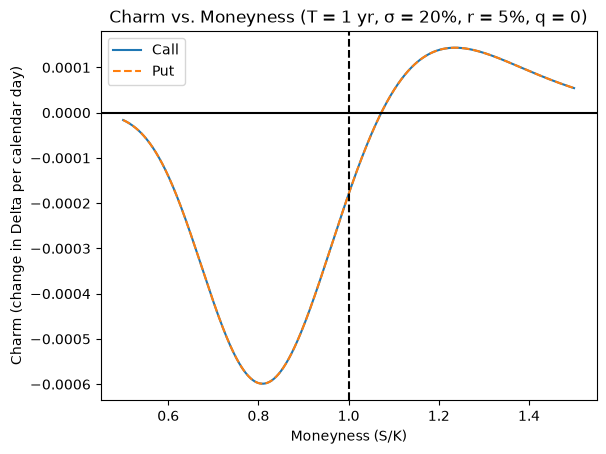

Most negative: S/K = 0.809, charm = -0.000599
Most positive: S/K = 1.236, charm = 0.000144
Charm turns positive at S/K = 1.073
Largest difference between call and put charm: 0.0


In [6]:
call_charm = charm(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")
put_charm = charm(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "put")

plt.plot(moneyness, call_charm, label="Call")
plt.plot(moneyness, put_charm, linestyle="--", label="Put")
plt.axhline(0, color="black")
plt.axvline(1, color="black", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Charm (change in Delta per calendar day)")
plt.title("Charm vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

print(f"Most negative: S/K = {moneyness[np.argmin(call_charm)]:.3f}, charm = {call_charm.min():.6f}")
print(f"Most positive: S/K = {moneyness[np.argmax(call_charm)]:.3f}, charm = {call_charm.max():.6f}")
print(f"Charm turns positive at S/K = {moneyness[np.argmax(call_charm > 0)]:.3f}")
print(f"Largest difference between call and put charm: {np.abs(call_charm - put_charm).max()}")

### Observations

1. **Charm is negative below $S/K \approx 1.073$ and positive above it:** for OTM and ATM calls, and calls up to about 7% in the money, Delta falls as time passes. For calls deeper in the money, it rises toward 1.

2. **The negative side is much stronger than the positive side:** Charm is most negative at $S/K \approx 0.809$ (−0.000599 per day) and most positive at $S/K \approx 1.236$ (+0.000144), about four times smaller. The next plot shows why: with $r > q$, the drift part is negative everywhere, so it deepens the negative side and offsets most of the positive side.

3. **Calls slightly in the money still have falling Delta:** between $S/K = 1$ and about 1.073, the call is more likely than not to finish in the money, so we might expect its Delta to rise toward 1. Instead, the loss of expected growth as time passes (the drift part) outweighs that push.

4. **Far from the strike, Charm fades toward zero:** deep out of the money and deep in the money, Delta is already close to its final value (0 or 1), so there is little left to change.

5. **Calls and puts are identical:** the largest difference between them is exactly 0, because with $q = 0$ call Delta minus put Delta is always 1.

## Components of Charm vs Moneyness (Base Case)

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls, split into the convergence and drift parts, with the total Charm for comparison

The dividend part is zero everywhere because $q = 0$, so it is not plotted. With $q = 0$, the put's parts are identical to the call's.

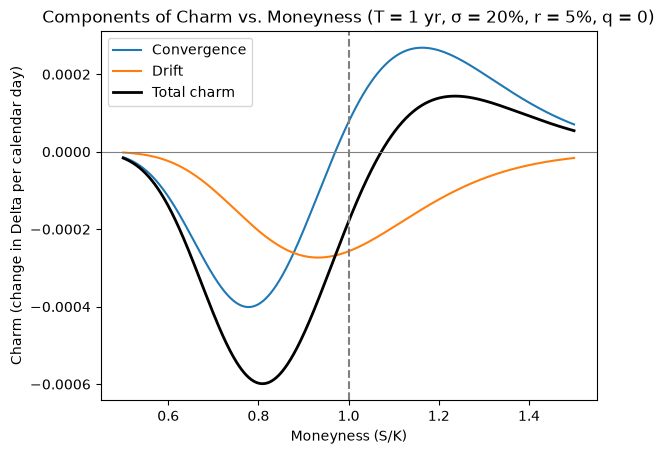

Convergence part changes sign at S/K = 0.971
Convergence part is most negative at S/K = 0.778 (-0.000401) and most positive at S/K = 1.163 (0.000269)
Drift part is most negative at S/K = 0.932 (-0.000273)


In [7]:
convergence, drift, dividend = charm_parts(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")

plt.plot(moneyness, convergence, label="Convergence")
plt.plot(moneyness, drift, label="Drift")
plt.plot(moneyness, convergence + drift + dividend, color="black", linewidth=2, label="Total charm")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Charm (change in Delta per calendar day)")
plt.title("Components of Charm vs. Moneyness (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

print(f"Convergence part changes sign at S/K = {moneyness[np.argmax(convergence > 0)]:.3f}")
print(f"Convergence part is most negative at S/K = {moneyness[np.argmin(convergence)]:.3f} ({convergence.min():.6f}) "
      f"and most positive at S/K = {moneyness[np.argmax(convergence)]:.3f} ({convergence.max():.6f})")
print(f"Drift part is most negative at S/K = {moneyness[np.argmin(drift)]:.3f} ({drift.min():.6f})")

### Observations

1. **The convergence part changes sign at $S/K \approx 0.971$:** this is where $d_2 = 0$, the 50-50 point. It is the same point where Theta's volatility decay peaked in notebook 01 (0.970 there, up to the grid spacing), the point of greatest uncertainty about the outcome. Below it, call Delta is pushed down toward 0; above it, up toward 1. The push is strongest a moderate distance from the strike, most negative at $S/K \approx 0.778$ (−0.000401) and most positive at $S/K \approx 1.163$ (+0.000269), and it fades further out because Delta is already close to 0 or 1.

2. **The drift part is negative everywhere:** with $r = 5\%$ and $q = 0$, the stock's expected growth over the remaining time shrinks every day, lowering Delta. It is most negative at $S/K \approx 0.932$ (−0.000273), near the money where $N'(d_1)$ peaks, and fades far from the strike.

3. **Adding the two parts:** the drift part pulls the whole convergence curve down. So the total crosses zero not at the 50-50 point (0.971) but further in the money, at 1.073. Its negative side reaches −0.000599 while its positive side reaches only +0.000144.

## Charm as the Slope of Theta

Charm can also be read as $\frac{\partial \Theta}{\partial S}$: the slope of the Theta curve from notebook 01. This plot checks that numerically. The slope of the call Theta curve is estimated with `np.gradient`, which divides the change in Theta between neighbouring grid points by the change in $S$. It is then compared with the Charm formula.

Theta per day divided by a change in stock price is a change in Delta per day, so the two are in the same units.

- **Varying:** stock price $S$ from 50 to 150, so moneyness $S/K$ runs from 0.5 to 1.5
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** call Theta (top), and call Charm with the slope of the Theta curve (bottom). The red dotted line marks where Theta is most negative.

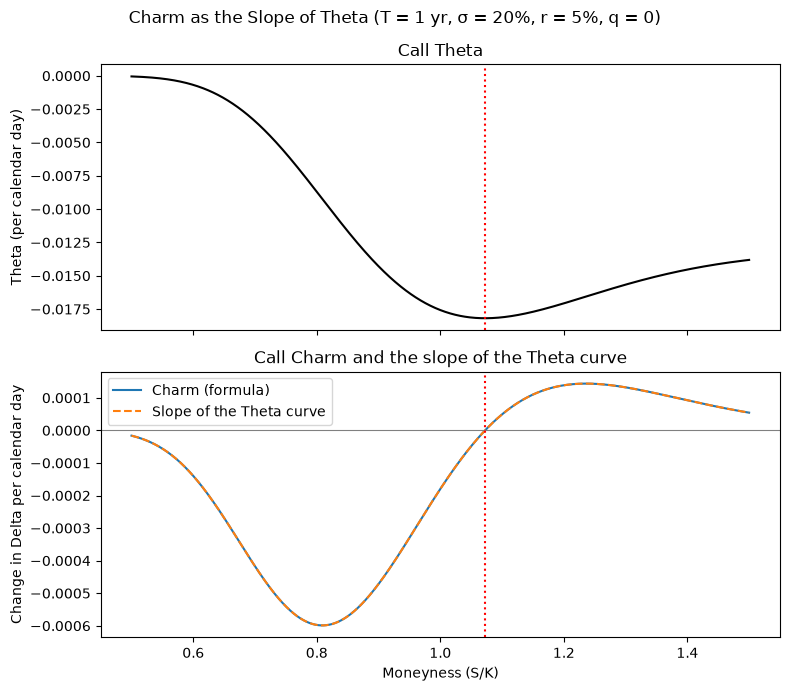

Theta is most negative at S/K = 1.073
Charm turns positive at S/K = 1.073
Largest gap between Charm and the Theta slope: 2.34e-07


In [8]:
theta_call = theta(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")
charm_call = charm(S_GRID, K, T_BASE, R_BASE, Q_BASE, SIGMA_BASE, "call")
theta_slope = np.gradient(theta_call, S_GRID)
theta_min = moneyness[np.argmin(theta_call)]

fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

ax_top.plot(moneyness, theta_call, color="black")
ax_top.set_ylabel("Theta (per calendar day)")
ax_top.set_title("Call Theta")

ax_bottom.plot(moneyness, charm_call, label="Charm (formula)")
ax_bottom.plot(moneyness, theta_slope, linestyle="--", label="Slope of the Theta curve")
ax_bottom.axhline(0, color="gray", linewidth=0.8)
ax_bottom.set_ylabel("Change in Delta per calendar day")
ax_bottom.set_xlabel("Moneyness (S/K)")
ax_bottom.set_title("Call Charm and the slope of the Theta curve")
ax_bottom.legend()

for ax in (ax_top, ax_bottom):
    ax.axvline(theta_min, color="red", linestyle=":")

fig.suptitle("Charm as the Slope of Theta (T = 1 yr, σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

print(f"Theta is most negative at S/K = {theta_min:.3f}")
print(f"Charm turns positive at S/K = {moneyness[np.argmax(charm_call > 0)]:.3f}")
print(f"Largest gap between Charm and the Theta slope: {np.abs(charm_call - theta_slope).max():.2e}")

### Observations

1. **The two curves match:** Charm from the formula and the slope of the Theta curve lie on top of each other. The largest gap, about $2 \times 10^{-7}$, comes from the cruder slope estimate `np.gradient` uses at the first and last grid points, and is tiny compared with Charm values of order $10^{-4}$.

2. **Charm is zero exactly where Theta is deepest:** both at $S/K \approx 1.073$. At the bottom of the Theta curve its slope is zero, so Charm is zero. To the left, Theta gets more negative as $S$ rises (negative slope, negative Charm); to the right, it gets less negative (positive slope, positive Charm).

3. **Two views of the same number:** Theta is how much the option's value changes per day; Charm is how that daily change itself varies with the stock price, which is the same as how Delta changes per day. So the shape of the Theta curves in notebook 01 tells us the sign of Charm: wherever a Theta curve falls as $S$ rises, Charm is negative, and wherever it rises, Charm is positive. With $q = 0$, put Theta is call Theta shifted by a constant, so it has the same slope and the same Charm.

## Charm vs Moneyness at Different Maturities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for four maturities: 1 week, 1 month, 3 months and 1 year
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$
- **Shows:** calls only (put Charm is identical when $q = 0$)

Charm's size changes by a factor of about 30 between 1 year and 1 week, so each maturity gets its own panel with its own y-axis scale. The printed lines give the exact values for comparing across panels.

T = 1 week: most negative -0.018996 at S/K = 0.973, most positive 0.015649 at S/K = 1.028, turns positive at S/K = 1.002
T = 1 month: most negative -0.004881 at S/K = 0.944, most positive 0.003265 at S/K = 1.059, turns positive at S/K = 1.006
T = 3 months: most negative -0.001850 at S/K = 0.904, most positive 0.000920 at S/K = 1.106, turns positive at S/K = 1.018
T = 1 year: most negative -0.000599 at S/K = 0.809, most positive 0.000144 at S/K = 1.236, turns positive at S/K = 1.073


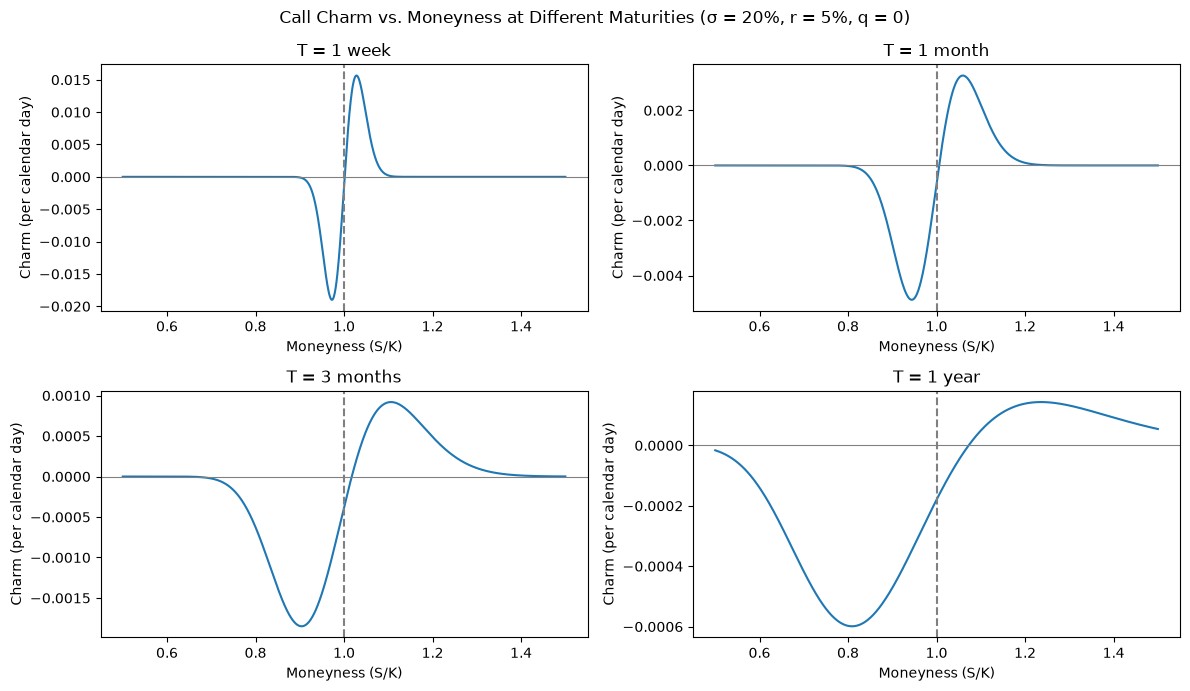

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (label, T) in zip(axes.flat, MATURITIES.items()):
    c = charm(S_GRID, K, T, R_BASE, Q_BASE, SIGMA_BASE, "call")
    ax.plot(moneyness, c)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(f"T = {label}")
    ax.set_xlabel("Moneyness (S/K)")
    ax.set_ylabel("Charm (per calendar day)")
    print(f"T = {label}: most negative {c.min():.6f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.6f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"turns positive at S/K = {moneyness[np.argmax(c > 0)]:.3f}")

fig.suptitle("Call Charm vs. Moneyness at Different Maturities (σ = 20%, r = 5%, q = 0)")
plt.tight_layout()
plt.show()

### Observations

1. **Charm grows sharply as expiry approaches:** the most negative Charm goes from −0.000599 per day at 1 year to −0.001850 at 3 months, −0.004881 at 1 month and −0.018996 at 1 week; the most positive goes from +0.000144 to +0.015649. With a week left, an option just below the strike can lose almost 0.02 of Delta in a single day. This comes from the $\frac{1}{T}$ factor in the convergence part: Delta has to complete its move to 0 or 1 in the time that remains.

2. **The action concentrates near the strike:** the extremes move in from $S/K \approx 0.809$ and $1.236$ at 1 year to $0.973$ and $1.028$ at 1 week. As with Theta, with only a week left the stock can realistically move only a few percent, so only options within a few percent of the strike still have Deltas in transition. Every other option's Delta is already at 0 or 1, so its Charm is close to zero.

3. **The two sides become more balanced:** at 1 year the negative side is about four times stronger than the positive side, but at 1 week they are similar (−0.0190 vs +0.0156). Near expiry, the convergence part (which grows like $\frac{1}{T}$) outgrows the drift part (which grows only like $\frac{1}{\sqrt{T}}$), so the curve looks more like the convergence part alone.

4. **The sign change moves toward ATM:** Charm turns positive at $S/K \approx 1.073$ at 1 year, 1.018 at 3 months, 1.006 at 1 month and 1.002 at 1 week. These match, to within the grid spacing, the deepest points of the Theta curves for the same maturities in notebook 01, as expected since Charm is the slope of Theta.

## Charm vs Time to Maturity

- **Varying:** time to maturity, from 1 day to 2 years in steps of one calendar day
- **Held constant:** $K = 100$, $\sigma = 20\%$, $r = 5\%$, $q = 0$, at three moneyness levels: $S/K = 0.9$, $1.0$ and $1.1$
- **Shows:** calls only. Put Charm is identical when $q = 0$; for puts, $S/K = 0.9$ is ITM and $1.1$ is OTM.

The x-axis uses a log scale, so the last few weeks before expiry are not squeezed into a sliver at the left edge. Moving left along the axis means time passing, i.e. getting closer to expiry. The table gives Charm at five checkpoints, the maturity at which Charm is largest in size, and the maturity at which it changes sign, if it does.

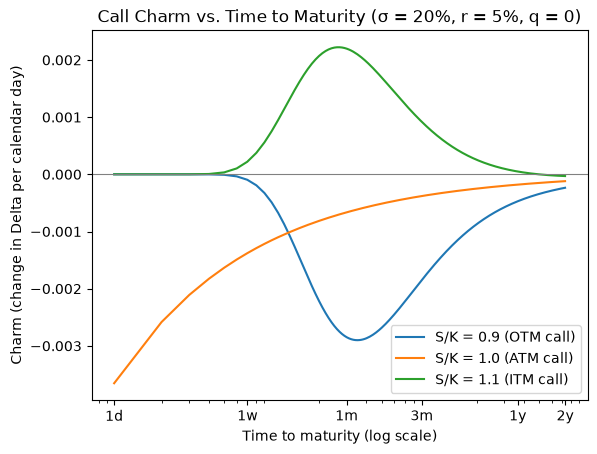

,S/K,type,1 day,1 week,1 month,1 year,2 years,largest at (days),changes sign at (days)
0,0.9,OTM,-0.000000,-0.000095,-0.002850,-0.000472,-0.000235,35,never
1,1.0,ATM,-0.003654,-0.001380,-0.000664,-0.000180,-0.000120,1,never
2,1.1,ITM,0.000000,0.000219,0.002197,0.000049,-0.000031,27,497


In [10]:
labels = {0.9: "OTM", 1.0: "ATM", 1.1: "ITM"}
rows = []

for m in MONEYNESS_LEVELS:
    c = charm(m * K, K, T_GRID, R_BASE, Q_BASE, SIGMA_BASE, "call")
    plt.plot(DAYS, c, label=f"S/K = {m} ({labels[m]} call)")
    flips = DAYS[1:][np.diff(np.sign(c)) != 0]
    # c[i] is Charm with i + 1 days to maturity
    rows.append({"S/K": m, "type": labels[m],
                 "1 day": c[0], "1 week": c[6], "1 month": c[29],
                 "1 year": c[364], "2 years": c[729],
                 "largest at (days)": np.argmax(np.abs(c)) + 1,
                 "changes sign at (days)": ", ".join(str(d) for d in flips) or "never"})

plt.xscale("log")
plt.xticks([1, 7, 30, 90, 365, 730], ["1d", "1w", "1m", "3m", "1y", "2y"])
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Time to maturity (log scale)")
plt.ylabel("Charm (change in Delta per calendar day)")
plt.title("Call Charm vs. Time to Maturity (σ = 20%, r = 5%, q = 0)")
plt.legend()
plt.show()

pd.DataFrame(rows).round(6)

### Observations

1. **ATM: Charm grows without limit as expiry approaches:** −0.000120 per day at 2 years, −0.000180 at 1 year, −0.000664 at 1 month, −0.001380 at 1 week and −0.003654 at 1 day, and it never changes sign. At the money, both the convergence and drift parts grow like $\frac{1}{\sqrt{T}}$, and the drift part is the larger of the two, so ATM Delta slides toward 0.5 ever faster as expiry nears.

2. **OTM call ($S/K = 0.9$): strongest at intermediate maturities:** Charm is close to zero right before expiry, because Delta has already reached 0, and small at long maturities, because Delta changes slowly when plenty of time remains. In between it is strongest, at about 35 days to maturity (−0.002850 at 1 month). This is a turning point: moving toward expiry, the drift in Delta first speeds up, then fades away.

3. **ITM call ($S/K = 1.1$): strongest at intermediate maturities, and changes sign:** for shorter maturities, Charm is positive and strongest at about 27 days (+0.002197 at 1 month), as Delta climbs toward 1. But for maturities longer than 497 days (about 1.36 years), Charm turns negative (−0.000031 at 2 years). With more time left, more of the option's chance of finishing in the money comes from the stock's expected growth, so the drift part outweighs the convergence part. This matches the sign-change point from the maturity plot, $S/K = e^{(r + \sigma^2/2)T}$ when $q = 0$, which equals 1.1 at $T = \ln(1.1)/0.07 \approx 1.36$ years.

4. **The same two speeds as Theta:** at the money, Charm is strongest at the shortest maturity; away from the money, it is strongest at intermediate maturities. This mirrors the pattern found for Theta in notebook 01.

## Charm vs Moneyness at Different Volatilities

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three volatilities: $\sigma = 10\%$, $20\%$ and $40\%$
- **Held constant:** $K = 100$, $T = 1$ year, $r = 5\%$, $q = 0$
- **Shows:** calls only (put Charm is identical when $q = 0$)

σ = 10%: most negative -0.000776 at S/K = 0.892, most positive 0.000077 at S/K = 1.121, turns positive at S/K = 1.057
σ = 20%: most negative -0.000599 at S/K = 0.809, most positive 0.000144 at S/K = 1.236, turns positive at S/K = 1.073
σ = 40%: most negative -0.000578 at S/K = 0.657, most positive 0.000154 at S/K = 1.500, turns positive at S/K = 1.139


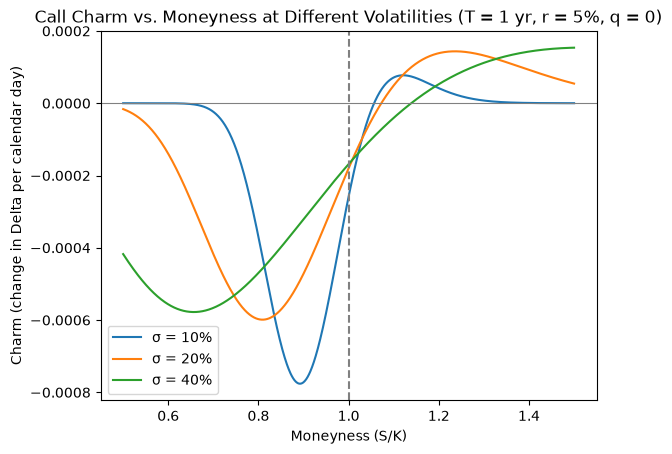

In [11]:
for sigma in SIGMAS:
    c = charm(S_GRID, K, T_BASE, R_BASE, Q_BASE, sigma, "call")
    plt.plot(moneyness, c, label=f"σ = {sigma:.0%}")
    print(f"σ = {sigma:.0%}: most negative {c.min():.6f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.6f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"turns positive at S/K = {moneyness[np.argmax(c > 0)]:.3f}")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Charm (change in Delta per calendar day)")
plt.title("Call Charm vs. Moneyness at Different Volatilities (T = 1 yr, r = 5%, q = 0)")
plt.legend()
plt.show()

### Observations

1. **Lower volatility concentrates Charm near the strike:** at $\sigma = 10\%$ the negative dip is deepest (−0.000776 at $S/K \approx 0.892$) and narrow; at 40% it is shallower (−0.000578) and spread wide, with its deepest point all the way out at $S/K \approx 0.657$. With low volatility the stock is unlikely to move far, so only options close to the strike still have Deltas in transition, and the Delta curve is steep there. With high volatility, Deltas far from the strike are still in transition, so Charm is spread over a wider range. This is the opposite of Theta, where higher volatility made decay larger; for Charm, higher volatility spreads the effect out rather than increasing it.

2. **The positive side is very weak at low volatility:** at 10%, the most positive Charm is only +0.000077, a tenth of the negative side. The drift part has $\sigma$ in its denominator: with small random swings, the stock's expected growth matters relatively more, so the drift part is large and drags the whole curve down.

3. **The sign change moves right as volatility rises:** from $S/K \approx 1.057$ at 10% to 1.073 at 20% and 1.139 at 40%, matching the deepest points of Theta at the same volatilities in notebook 01.

4. **At 40%, the positive peak lies beyond the plotted range:** the printed maximum (+0.000154) sits at the edge, $S/K = 1.5$. Higher volatility spreads everything out, so the true peak is further in the money.

## Charm vs Moneyness at Different Interest Rates

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three risk-free rates: $r = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $q = 0$
- **Shows:** calls only (put Charm is identical when $q = 0$)

$r = 0\%$ is included as a baseline: the drift part is proportional to $r - q$, so with $r = q = 0$ only the convergence part remains.

r = 0%: most negative -0.000401 at S/K = 0.818, most positive 0.000269 at S/K = 1.223, turns positive at S/K = 1.021, ATM -0.000054
r = 5%: most negative -0.000599 at S/K = 0.809, most positive 0.000144 at S/K = 1.236, turns positive at S/K = 1.073, ATM -0.000180
r = 10%: most negative -0.000822 at S/K = 0.792, most positive 0.000065 at S/K = 1.263, turns positive at S/K = 1.128, ATM -0.000274


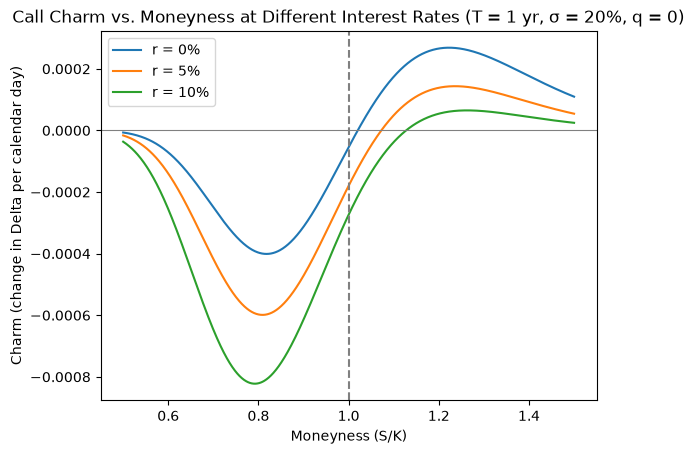

In [12]:
for rate in RATES:
    c = charm(S_GRID, K, T_BASE, rate, Q_BASE, SIGMA_BASE, "call")
    plt.plot(moneyness, c, label=f"r = {rate:.0%}")
    print(f"r = {rate:.0%}: most negative {c.min():.6f} at S/K = {moneyness[np.argmin(c)]:.3f}, "
          f"most positive {c.max():.6f} at S/K = {moneyness[np.argmax(c)]:.3f}, "
          f"turns positive at S/K = {moneyness[np.argmax(c > 0)]:.3f}, "
          f"ATM {charm(K, K, T_BASE, rate, Q_BASE, SIGMA_BASE, 'call'):.6f}")

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Moneyness (S/K)")
plt.ylabel("Charm (change in Delta per calendar day)")
plt.title("Call Charm vs. Moneyness at Different Interest Rates (T = 1 yr, σ = 20%, q = 0)")
plt.legend()
plt.show()

### Observations

1. **$r = 0\%$ shows the convergence part alone:** Charm is negative below $S/K \approx 1.021$ and positive above it, which is exactly the 50-50 point ($d_2 = 0$) when $r = 0$. The two sides are closer in size (−0.000401 and +0.000269), and ATM Charm is only −0.000054.

2. **Higher rates push Charm down:** a higher rate means more expected growth over the remaining time, so more of it is lost each day. The most negative Charm goes from −0.000401 at 0% to −0.000599 at 5% and −0.000822 at 10%, the most positive shrinks from +0.000269 to +0.000144 and +0.000065, and ATM Charm falls from −0.000054 to −0.000180 and −0.000274.

3. **The sign change moves into the money:** from $S/K \approx 1.021$ to 1.073 and 1.128, matching, to within the grid spacing, the deepest points of Theta at the same rates in notebook 01.

4. **The rate effect fades far from the strike:** the drift part is weighted by $N'(d_1)$, which is small far from the strike, so the three curves come together near zero at both edges.

## Charm vs Moneyness at Different Dividend Yields

- **Varying:** stock price $S$ from 50 to 150 (moneyness $S/K$ from 0.5 to 1.5), for three dividend yields: $q = 0\%$, $5\%$ and $10\%$
- **Held constant:** $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$
- **Shows:** calls (left) and puts (right). With $q > 0$, call and put Charm differ, so both are shown.

The printed lines also check that call Charm minus put Charm equals $\frac{qe^{-qT}}{365}$ at every stock price.

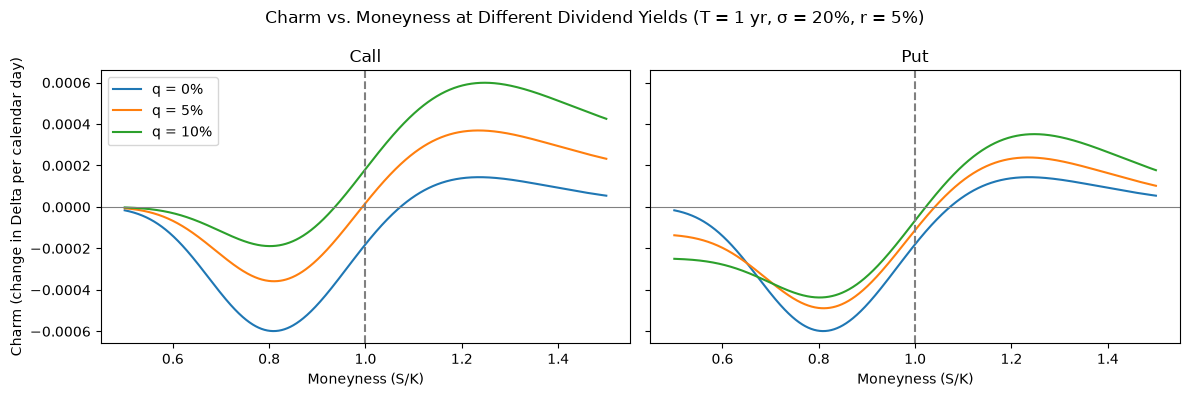

q = 0%: call -0.000599 to 0.000144, turns positive at S/K = 1.073; put -0.000599 to 0.000144, turns positive at S/K = 1.073
        call minus put: 0.000000 to 0.000000, q·e^(−qT)/365 = 0.000000
q = 5%: call -0.000358 to 0.000369, turns positive at S/K = 0.994; put -0.000489 to 0.000239, turns positive at S/K = 1.041
        call minus put: 0.000130 to 0.000130, q·e^(−qT)/365 = 0.000130
q = 10%: call -0.000189 to 0.000599, turns positive at S/K = 0.937; put -0.000437 to 0.000351, turns positive at S/K = 1.023
        call minus put: 0.000248 to 0.000248, q·e^(−qT)/365 = 0.000248


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, option in zip(axes, ["call", "put"]):
    for q in DIV_YIELDS:
        ax.plot(moneyness, charm(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, option), label=f"q = {q:.0%}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(1, color="gray", linestyle="--")
    ax.set_title(option.capitalize())
    ax.set_xlabel("Moneyness (S/K)")

axes[0].set_ylabel("Charm (change in Delta per calendar day)")
axes[0].legend()
fig.suptitle("Charm vs. Moneyness at Different Dividend Yields (T = 1 yr, σ = 20%, r = 5%)")
plt.tight_layout()
plt.show()

for q in DIV_YIELDS:
    c = charm(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "call")
    p = charm(S_GRID, K, T_BASE, R_BASE, q, SIGMA_BASE, "put")
    print(f"q = {q:.0%}: call {c.min():.6f} to {c.max():.6f}, turns positive at S/K = {moneyness[np.argmax(c > 0)]:.3f}; "
          f"put {p.min():.6f} to {p.max():.6f}, turns positive at S/K = {moneyness[np.argmax(p > 0)]:.3f}")
    print(f"        call minus put: {(c - p).min():.6f} to {(c - p).max():.6f}, "
          f"q·e^(−qT)/365 = {q * np.exp(-q * T_BASE) / DAYS_PER_YEAR:.6f}")

### Observations

1. **Dividends raise call Charm:** the call curve moves up as $q$ rises. Its most negative value goes from −0.000599 at $q = 0\%$ to −0.000358 at 5% and −0.000189 at 10%, its most positive from +0.000144 to +0.000369 and +0.000599, and it turns positive earlier: at $S/K \approx 1.073$, 0.994 and 0.937. Two parts push the same way for calls:
   - the **dividend part** is positive: fewer dividends remain as time passes, so $e^{-qT}$ and call Delta rise;
   - the **drift part** is proportional to $-(r - q)$: it shrinks to zero at $q = r = 5\%$ and turns positive at $q = 10\%$, when the stock is expected to shrink rather than grow over the remaining time.

2. **For puts, the two parts pull in opposite directions:** the drift part rises with $q$ just as for calls, but the dividend part is negative for puts (put Delta heads toward −1 as $e^{-qT}$ rises). The dividend part dominates deep in the money (left side), where higher $q$ makes put Charm more negative, while the drift part dominates near the money, where higher $q$ lifts put Charm. As a result, put Charm turns positive at $S/K \approx 1.073$, 1.041 and 1.023.

3. **The call–put gap is constant:** call Charm minus put Charm is 0.000130 at $q = 5\%$ and 0.000248 at $q = 10\%$ at every $S/K$, exactly $\frac{qe^{-qT}}{365}$. Call Delta minus put Delta equals $e^{-qT}$ whatever the stock price, and that gap grows by $qe^{-qT}$ per year as time passes. This is different from Theta in notebook 01, where the call–put gap depended on $S$ once $q > 0$.

## Summary

All Charm values are per calendar day, i.e. the change in Delta over one day. Unless stated otherwise: $K = 100$, $T = 1$ year, $\sigma = 20\%$, $r = 5\%$, $q = 0$.

### What Charm measures, and its link to Delta and Theta

- Charm is the daily drift in Delta when the stock price does not move. In the base-case table, it matches the actual one-day change in Delta to six decimal places.
- As expiry approaches, the Delta curve sharpens into a step (1 above the strike, 0 below for calls), and Charm measures how fast each option's Delta moves toward its final value.
- Charm is also the slope of the Theta curve: the numerical slope of Theta matches the formula, and Charm is zero exactly where Theta is deepest ($S/K \approx 1.073$ in the base case).

### Where Charm reaches its extremes

- In the base case, Charm is most negative at $S/K \approx 0.809$ (−0.000599), most positive at $S/K \approx 1.236$ (+0.000144), and zero at $S/K \approx 1.073$.
- As expiry approaches, the extremes grow sharply and move toward the strike: −0.0190 and +0.0156 per day at 1 week, at $S/K \approx 0.973$ and 1.028.

### Sign, and calls vs puts

- Charm is negative below its sign-change point (Delta falls as time passes) and positive above it (Delta rises). With $q = 0$, the sign-change point is $S/K = e^{(r + \sigma^2/2)T}$, the same point where Theta is deepest.
- With $q = 0$, call and put Charm are identical, because call Delta minus put Delta is always 1. With $q > 0$, call Charm exceeds put Charm by the constant $\frac{qe^{-qT}}{365}$ at every stock price.

### Across moneyness

- **OTM calls:** Delta falls toward 0, so Charm is negative.
- **ATM:** Charm is negative in the base case: the drift part outweighs the convergence part, and Delta slides toward 0.5.
- **ITM calls beyond the sign-change point:** Delta rises toward 1, so Charm is positive.
- **Far from the strike:** Delta has already reached its final value, so Charm fades toward zero.

### Effect of each parameter

- **Time to maturity:** Charm grows sharply as expiry approaches, because of the $\frac{1}{T}$ factor in the convergence part, and becomes concentrated in a narrow band around the strike. ATM Charm grows without limit (−0.000180 at 1 year to −0.003654 at 1 day).
- **Volatility:** lower volatility makes Charm more concentrated near the strike and strengthens the drift part, so the negative side dominates; higher volatility spreads Charm over a wider range.
- **Risk-free rate:** higher $r$ makes the drift part more negative, lowering Charm near the money and moving the sign change further in the money.
- **Dividend yield:** higher $q$ raises call Charm (through both the dividend and drift parts). For puts, it lowers Charm deep in the money but raises it near the money.

### Turning points and nonlinearities

- Charm changes sign across moneyness; with $q = 0$ the sign change sits at $S/K = e^{(r + \sigma^2/2)T}$, moving toward ATM as expiry approaches.
- Against time to maturity, OTM and ITM call Charm are strongest at intermediate maturities (about 35 and 27 days), while ATM Charm is strongest at the shortest maturity.
- ITM call Charm ($S/K = 1.1$) changes sign with maturity: positive below about 497 days, negative above.

### Comparison with class material

- **Matches the Delta reference notebook:** its Delta-vs-moneyness plot at different maturities shows the Delta curve steepening as maturity shortens. Charm measures how fast that steepening happens for each option.
- **Extends it:** the speed is not uniform. It depends on moneyness, explodes near expiry, and its sign is set by a balance between convergence toward 0 or 1, the loss of expected growth, and dividends.